# CP2 — Improving the Advisor-Score Regressors

Dedicated workspace for the **validity** half of the challenge: predicting the four advisors' scores
for unlabeled grids. No diversity/selection work happens here.

Structure:
1. Bootstrap + data loading (same as the starter notebook)
2. A small experiment harness: pick a feature encoding + a model, get per-advisor train/test R² and plots
3. Baseline experiments (linear regression on raw labels, counts, one-hot)
4. Nonlinear models (random forest, gradient boosting)
5. A running comparison table
6. Calibration near the 0.75 validity threshold — the number that actually matters downstream

In [42]:
# Bootstrap - runs both on Colab and locally in the ps2 repo.
#
# Colab clones the course repo into /content. Locally we reuse the clone that
# ./setup_data.sh puts in data/cp2-repo (gitignored: ~70 MB of course data that
# is not ours to commit). Either way we chdir into it, because utils_public.py
# resolves "datasets/..." and "assets/..." relative to the working directory.
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
COURSE_REPO = "https://github.com/decode-mit/2155-CP2-2026.git"


def _ps2_root(start):
    """Walk up from `start` to the ps2 repo root (the dir holding environment.yml)."""
    d = os.path.abspath(start)
    while True:
        if os.path.exists(os.path.join(d, "environment.yml")):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise RuntimeError(f"could not find the ps2 repo root above {start}")
        d = parent


if IN_COLAB:
    COURSE_ROOT = "/content/2155-CP2-2026"
    SUBMISSION_DIR = "/content/submissions"
else:
    # Re-running this cell is safe: cwd is then the course clone, and walking
    # up from data/cp2-repo still lands on the ps2 root.
    PS2_ROOT = _ps2_root(os.getcwd())
    COURSE_ROOT = os.path.join(PS2_ROOT, "data", "cp2-repo")
    SUBMISSION_DIR = os.path.join(PS2_ROOT, "submissions")

if not os.path.isdir(COURSE_ROOT):
    subprocess.run(["git", "clone", "--depth", "1", COURSE_REPO, COURSE_ROOT], check=True)

os.chdir(COURSE_ROOT)
sys.path.insert(0, COURSE_ROOT)
os.makedirs(SUBMISSION_DIR, exist_ok=True)

from utils_public import *

print(f"course data: {COURSE_ROOT}")
print(f"submissions: {SUBMISSION_DIR}")

course data: /Users/fb/repos/2.156-ps2/data/cp2-repo
submissions: /Users/fb/repos/2.156-ps2/submissions


## Load data
500k grids; each advisor labeled 5k of them (1%). `ADVISOR_NAMES` indexes columns of `ratings`.

In [43]:
import numpy as np
import pandas as pd

grids = load_grids()
ratings = np.load("datasets/scores.npy")
ADVISOR_NAMES = ["Wellness", "Tax", "Transportation", "Business"]

print(grids.shape, ratings.shape)
print("labels per advisor:", (~np.isnan(ratings)).sum(axis=0))

(500000, 7, 7) (500000, 4)
labels per advisor: [5000 5000 5000 5000]


## Experiment harness

One function to run an experiment: `(feature_fn, model_fn)` → per-advisor metrics, with optional
predicted-vs-actual plots. Results accumulate in `RESULTS` so encodings/models can be compared at the end.

**The primary metric is `recall@98p`, a 0-to-1 score where 1 is a perfect model.** Walk down the model's
prediction ranking, certifying grids as valid, for as long as the certified pool stays ≥ 98% truly valid
(true score ≥ 0.75). `recall@98p` is the fraction of *all* truly valid grids captured before stopping:

- **0** — the model can't certify anything at that trust level
- **1** — a perfect ranker: every genuinely valid grid certified, at most 1-in-50 duds

It reads directly as "what share of the valid designs out there can this model safely hand to the
selection stage?" The 98% purity bar comes from the joint constraint: four advisors each at 98% ⇒
~0.98⁴ ≈ 92% of submitted grids truly valid. A 0.76 and a 0.99 are equally valid for scoring, so global
fit (R²) is only a sanity check; what matters is ranking quality around the 0.75 boundary, with false
positives (invalid grids certified) heavily penalized.

Also recorded: **yield@98p** (same stopping point, as a fraction of all grids — the absolute pool size,
which the selection stage cares about; its ceiling is the ~25% valid fraction), **PR-AUC** on the
binarized label (cutoff-free ranking quality, a stabler tiebreaker), and train/test **R²**. Note we still
*train* on continuous scores — binarizing the scarce 5k labels would discard signal; the binary view is
for *evaluation*.

- A **feature_fn** maps an `(n, 7, 7)` grid array to an `(n, d)` feature matrix.
- A **model_fn** returns a fresh, unfitted sklearn-style regressor (so each advisor gets its own model).
- The split uses `random_state=0` everywhere, matching the starter notebook, so runs are comparable.
- `results_table()` shows `recall_at_98p` by default; pass `"yield_at_98p"`, `"pr_auc"`, or `"r2_test"`
  for the others.

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, r2_score
from sklearn.model_selection import train_test_split

RESULTS = []  # list of dicts; one row per (experiment, advisor)
VALID_THRESHOLD = 0.75


def certify_at_precision(preds, y_true, target=0.98):
    """Walk down the prediction ranking as far as cumulative precision allows.

    Returns (recall, yield_frac) at the deepest depth where the certified pool is still
    >= target precision (fraction truly valid among certified):
      - recall:      certified truly-valid grids / all truly-valid grids. 0 = model certifies
                     nothing at this trust level, 1 = perfect ranker (captures every valid grid).
      - yield_frac:  certified grids / all grids (the absolute pool size, max = valid fraction).
    """
    order = np.argsort(-preds)
    valid = (y_true[order] >= VALID_THRESHOLD)
    cum_valid = np.cumsum(valid)
    cum_precision = cum_valid / np.arange(1, len(valid) + 1)
    ok = np.where(cum_precision >= target)[0]
    if not ok.size:
        return 0.0, 0.0
    deepest = ok[-1]
    return cum_valid[deepest] / valid.sum(), (deepest + 1) / len(valid)


def run_experiment(name, feature_fn, model_fn, plot=True):
    """Train one model per advisor and record recall@98p, yield@98p, PR-AUC, train/test R2."""
    models = []
    if plot:
        fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharex=True, sharey=True)
    for advisor in range(4):
        grids_subset, ratings_subset = select_rated_subset(grids, ratings[:, advisor])
        X = feature_fn(grids_subset)
        X_train, X_test, y_train, y_test = train_test_split(X, ratings_subset, random_state=0)

        model = model_fn()
        model.fit(X_train, y_train)
        models.append(model)

        preds_train = model.predict(X_train)
        preds_test = model.predict(X_test)
        recall98, yield98 = certify_at_precision(preds_test, y_test)
        pr_auc = average_precision_score(y_test >= VALID_THRESHOLD, preds_test)
        RESULTS.append({"experiment": name, "advisor": ADVISOR_NAMES[advisor],
                        "recall_at_98p": recall98, "yield_at_98p": yield98, "pr_auc": pr_auc,
                        "r2_train": r2_score(y_train, preds_train),
                        "r2_test": r2_score(y_test, preds_test)})

        if plot:
            ax = axes[advisor]
            ax.scatter(y_train, preds_train, s=3, c="#BBBBBB", label="train")
            ax.scatter(y_test, preds_test, s=5, c="#DC267F", label="test")
            ax.plot([0, 1], [0, 1], c="k", linewidth=2)
            ax.axvline(VALID_THRESHOLD, c="#444444", linewidth=1, linestyle="--")
            ax.set_title(f"{ADVISOR_NAMES[advisor]}\nrecall@98p = {recall98:.2f}")
            ax.spines[["right", "top"]].set_visible(False)
    if plot:
        fig.suptitle(name)
        axes[0].set_ylabel("Predicted")
        for ax in axes:
            ax.set_xlabel("Actual")
        plt.tight_layout()
        plt.show()
    return models


def results_table(metric="recall_at_98p"):
    """Pivot RESULTS into experiments x advisors for one metric ('recall_at_98p', 'yield_at_98p',
    'pr_auc', 'r2_test', 'r2_train'), with a mean column; best experiment at the bottom."""
    df = pd.DataFrame(RESULTS).drop_duplicates(subset=["experiment", "advisor"], keep="last")
    table = df.pivot(index="experiment", columns="advisor", values=metric)[ADVISOR_NAMES]
    table["mean"] = table.mean(axis=1)
    return table.sort_values("mean")

## Feature encodings

- `raw_flat`: cell labels 0–4 as numbers (the starter's broken baseline — categories treated as quantities)
- `flat_plus_counts`: starter's fix — raw labels + per-district counts
- `onehot`: each cell as 5 binary features (245 total), via `onehot_and_flatten` from `utils_public`
- `onehot_plus_adjacency`: one-hot + counts of each (district, district) adjacent pair — 15 features
  encoding "what borders what" (e.g. residential next to park vs. next to industrial)

Add new encodings here as experiments suggest them.

In [45]:
def raw_flat(grids):
    return grids.reshape(-1, 49)


def flat_plus_counts(grids):
    flat = grids.reshape(-1, 49)
    counts = np.stack([(flat == d).sum(axis=1) for d in range(5)]).T
    return np.hstack([flat, counts])


def onehot(grids):
    return onehot_and_flatten(grids)  # from utils_public; (n, 245)


def adjacency_counts(grids):
    """Counts of unordered (district, district) pairs over all horizontally/vertically adjacent cells."""
    n = grids.shape[0]
    pairs = np.zeros((n, 5, 5), dtype=int)
    h_a, h_b = grids[:, :, :-1], grids[:, :, 1:]   # horizontal neighbors
    v_a, v_b = grids[:, :-1, :], grids[:, 1:, :]   # vertical neighbors
    for a, b in [(h_a, h_b), (v_a, v_b)]:
        lo = np.minimum(a, b).reshape(n, -1)
        hi = np.maximum(a, b).reshape(n, -1)
        np.add.at(pairs, (np.arange(n)[:, None], lo, hi), 1)
    iu = np.triu_indices(5)
    return pairs[:, iu[0], iu[1]]  # (n, 15)


def onehot_plus_adjacency(grids):
    return np.hstack([onehot(grids), adjacency_counts(grids)])

## Baselines: linear regression
Reproduce the starter's two baselines, then see what one-hot alone buys.

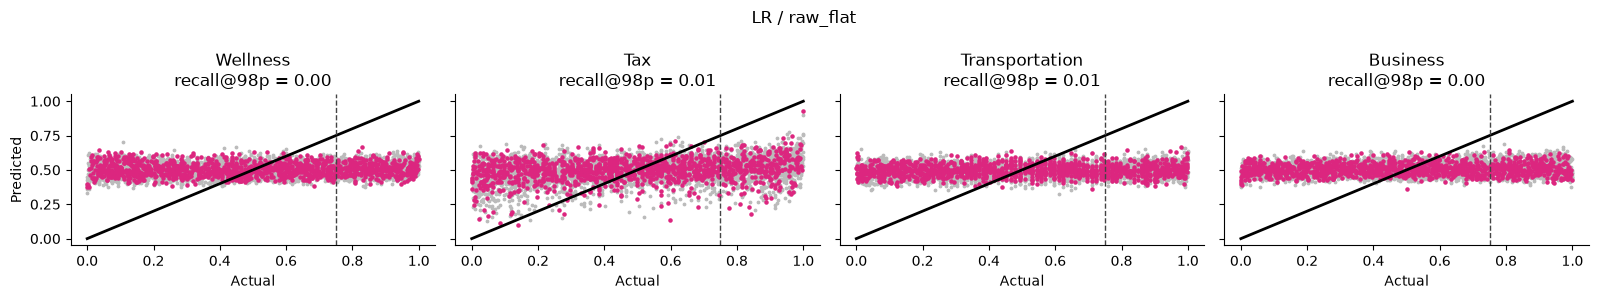

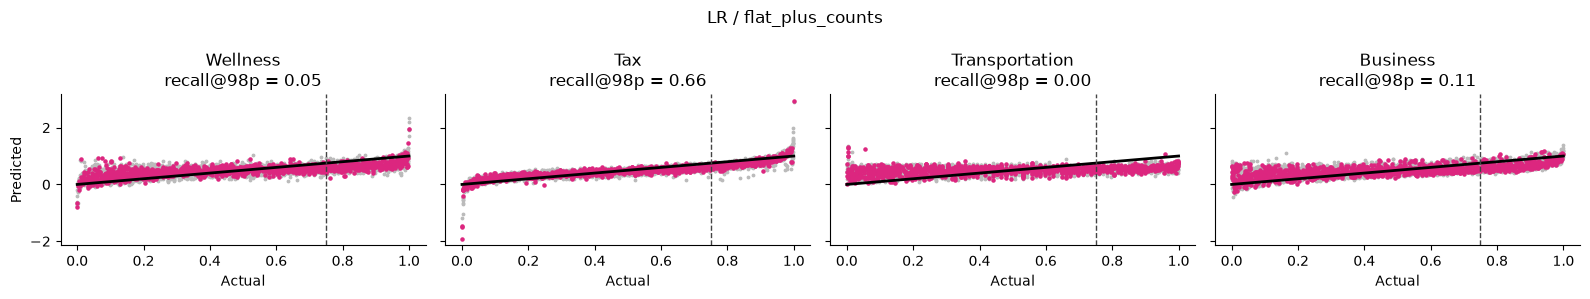

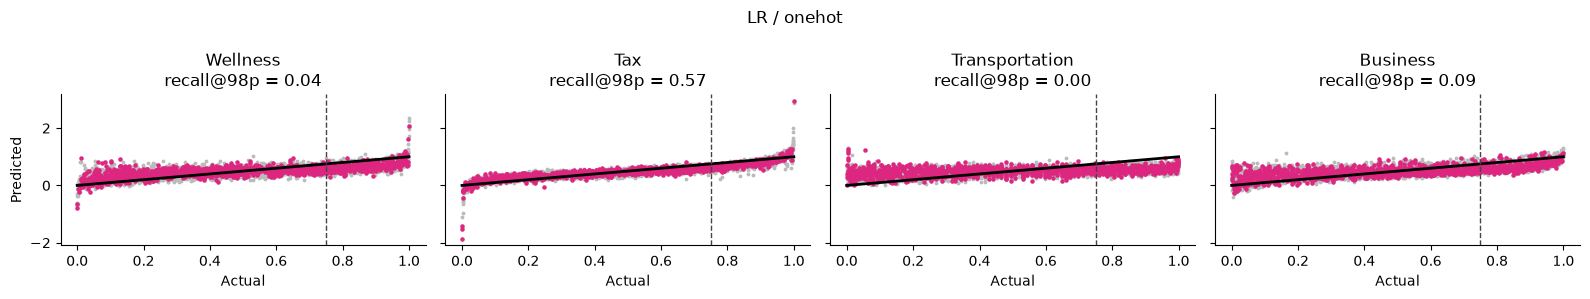

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
LR / raw_flat,0.003367,0.010453,0.009868,0.003413,0.006775
LR / onehot,0.043771,0.571429,0.000000,0.085324,0.175131
LR / flat_plus_counts,0.047138,0.662021,0.000000,0.105802,0.203740


In [46]:
from sklearn.linear_model import LinearRegression

run_experiment("LR / raw_flat", raw_flat, LinearRegression)
run_experiment("LR / flat_plus_counts", flat_plus_counts, LinearRegression)
run_experiment("LR / onehot", onehot, LinearRegression)
results_table()

## Nonlinear models
Advisors plausibly score *interactions* (what is next to what, how districts cluster), which linear
models on per-cell features cannot express. Tree ensembles are the cheapest way to test that.
`HistGradientBoostingRegressor` is fast enough to iterate on; tune `max_iter`/`learning_rate` later.

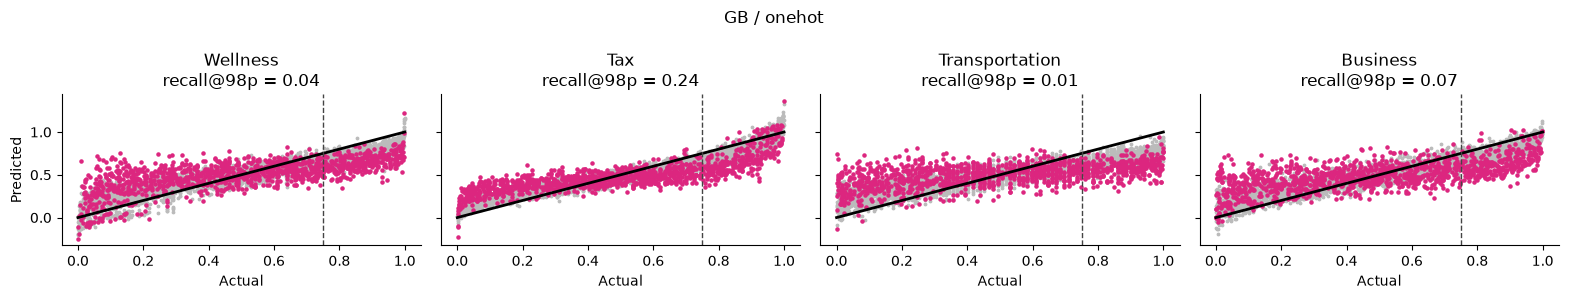

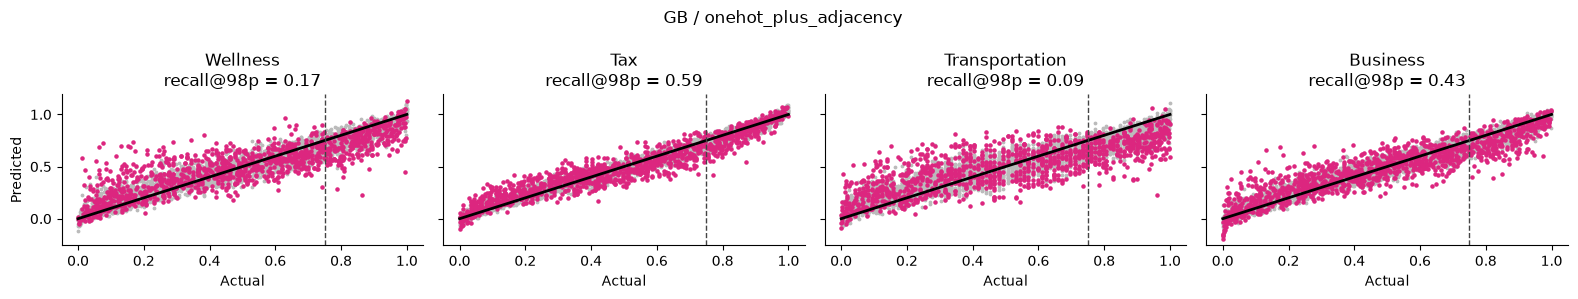

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
LR / raw_flat,0.003367,0.010453,0.009868,0.003413,0.006775
GB / onehot,0.040404,0.240418,0.009868,0.068259,0.089737
LR / onehot,0.043771,0.571429,0.000000,0.085324,0.175131
LR / flat_plus_counts,0.047138,0.662021,0.000000,0.105802,0.203740
GB / onehot_plus_adjacency,0.168350,0.588850,0.088816,0.426621,0.318159


In [47]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

run_experiment("GB / onehot", onehot,
               lambda: HistGradientBoostingRegressor(random_state=0))
run_experiment("GB / onehot_plus_adjacency", onehot_plus_adjacency,
               lambda: HistGradientBoostingRegressor(random_state=0))
results_table()

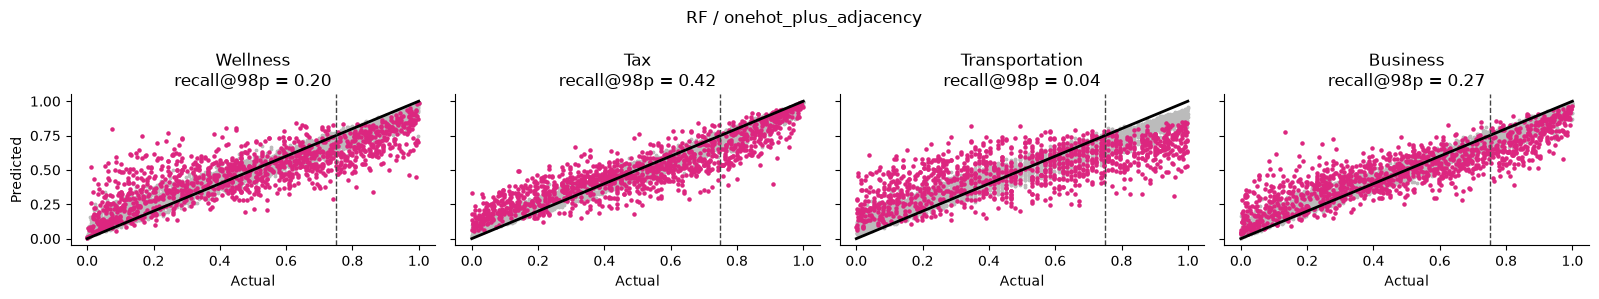

advisor,Wellness,Tax,Transportation,Business,mean
experiment,,,,,
LR / raw_flat,0.003367,0.010453,0.009868,0.003413,0.006775
GB / onehot,0.040404,0.240418,0.009868,0.068259,0.089737
LR / onehot,0.043771,0.571429,0.000000,0.085324,0.175131
LR / flat_plus_counts,0.047138,0.662021,0.000000,0.105802,0.203740
RF / onehot_plus_adjacency,0.202020,0.418118,0.036184,0.266212,0.230634
GB / onehot_plus_adjacency,0.168350,0.588850,0.088816,0.426621,0.318159


In [48]:
run_experiment("RF / onehot_plus_adjacency", onehot_plus_adjacency,
               lambda: RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0))
results_table()

## Calibration at the 0.75 threshold

Test R² is a proxy. What the selection step will actually ask the model is: *"if you predict this grid
clears 0.75, does it?"* An invalid grid in the submission scores zero, so false positives are what hurt.

For a range of prediction cutoffs, we measure on the held-out test set:
- **precision**: of grids predicted ≥ cutoff, the fraction truly ≥ 0.75 (want this near 1)
- **yield**: how many test grids clear the cutoff at all (if ~0, the cutoff is uselessly strict)

The smallest cutoff with near-perfect precision is the safety margin the selection notebook should use.

In [49]:
def calibration_at_threshold(feature_fn, model_fn, cutoffs=(0.75, 0.78, 0.80, 0.82, 0.85)):
    rows = []
    for advisor in range(4):
        grids_subset, ratings_subset = select_rated_subset(grids, ratings[:, advisor])
        X = feature_fn(grids_subset)
        X_train, X_test, y_train, y_test = train_test_split(X, ratings_subset, random_state=0)
        model = model_fn()
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        for cutoff in cutoffs:
            picked = preds >= cutoff
            n_picked = int(picked.sum())
            precision = float((y_test[picked] >= 0.75).mean()) if n_picked else np.nan
            rows.append({"advisor": ADVISOR_NAMES[advisor], "cutoff": cutoff,
                         "n_picked": n_picked, "precision": precision})
    return pd.DataFrame(rows).pivot(index="cutoff", columns="advisor", values=["n_picked", "precision"])


calibration_at_threshold(onehot_plus_adjacency, lambda: HistGradientBoostingRegressor(random_state=0))

n_picked                                precision            \
advisor Business    Tax Transportation Wellness  Business       Tax   
cutoff                                                                
0.75       209.0  238.0          164.0    187.0  0.894737  0.936975   
0.78       176.0  215.0          127.0    161.0  0.954545  0.953488   
0.80       150.0  192.0           93.0    142.0  0.973333  0.963542   
0.82       135.0  171.0           64.0    117.0  0.977778  0.982456   
0.85       111.0  142.0           41.0     95.0  0.990991  1.000000   

                                  
advisor Transportation  Wellness  
cutoff                            
0.75          0.725610  0.877005  
0.78          0.763780  0.900621  
0.80          0.806452  0.894366  
0.82          0.859375  0.905983  
0.85          0.951220  0.926316

### Visualizing the precision–yield tradeoff

The table samples five cutoffs; the curves below sweep the cutoff finely so the tension is visible.
For each advisor, one panel, both quantities as fractions on a single 0–1 axis:

- **precision** — of test grids predicted ≥ cutoff, the fraction truly ≥ 0.75
- **yield** — the fraction of all test grids predicted ≥ cutoff

Raising the cutoff pushes precision up and yield down; where the two curves sit tells you how expensive
safety is for that advisor. The dot marks the first cutoff whose precision reaches 95% — a reasonable
per-advisor safety margin to carry into the selection step. (Yield is per 1,250 test grids; even a few
percent scales to thousands of candidates over the 500k pool.)

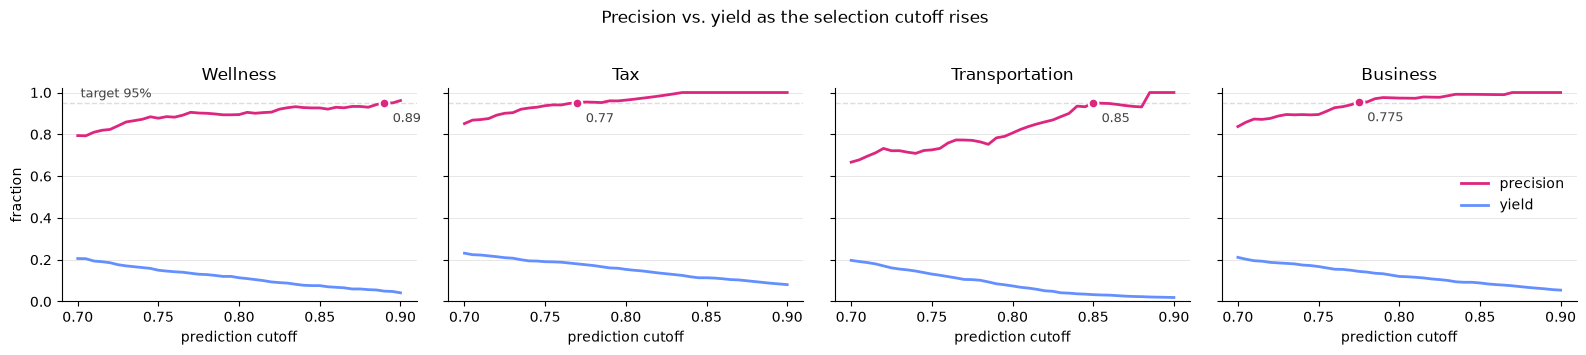

In [50]:
def plot_precision_yield_tradeoff(feature_fn, model_fn, cutoffs=np.arange(0.70, 0.901, 0.005),
                                  target_precision=0.95):
    """One panel per advisor: precision and yield (both fractions) vs. prediction cutoff."""
    C_PRECISION, C_YIELD, C_INK, C_GRID = "#DC267F", "#648FFF", "#444444", "#DDDDDD"
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharex=True, sharey=True)

    for advisor, ax in enumerate(axes):
        grids_subset, ratings_subset = select_rated_subset(grids, ratings[:, advisor])
        X = feature_fn(grids_subset)
        X_train, X_test, y_train, y_test = train_test_split(X, ratings_subset, random_state=0)
        model = model_fn()
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

        precision, yield_frac = [], []
        for c in cutoffs:
            picked = preds >= c
            yield_frac.append(picked.mean())
            precision.append((y_test[picked] >= 0.75).mean() if picked.any() else np.nan)
        precision, yield_frac = np.array(precision), np.array(yield_frac)

        ax.grid(axis="y", color=C_GRID, linewidth=0.5, zorder=0)
        ax.axhline(target_precision, color=C_GRID, linewidth=1, linestyle="--", zorder=1)
        ax.plot(cutoffs, precision, color=C_PRECISION, linewidth=2, label="precision", zorder=3)
        ax.plot(cutoffs, yield_frac, color=C_YIELD, linewidth=2, label="yield", zorder=3)

        # first cutoff whose precision reaches the target: the per-advisor safety margin
        ok = np.where(precision >= target_precision)[0]
        if ok.size:
            i = ok[0]
            ax.plot(cutoffs[i], precision[i], "o", color=C_PRECISION, markersize=7,
                    markeredgecolor="white", markeredgewidth=1.5, zorder=4)
            ax.annotate(f"{cutoffs[i]:.3g}", (cutoffs[i], precision[i]),
                        xytext=(6, -14), textcoords="offset points", color=C_INK, fontsize=9)

        ax.set_title(ADVISOR_NAMES[advisor])
        ax.set_xlabel("prediction cutoff")
        ax.set_ylim(0, 1.02)
        ax.spines[["right", "top"]].set_visible(False)

    # direct labels once, in ink, in the first panel; legend covers the rest
    axes[0].set_ylabel("fraction")
    axes[0].annotate(f"target {target_precision:.0%}", (cutoffs[0], target_precision),
                     xytext=(2, 4), textcoords="offset points", color=C_INK, fontsize=9)
    axes[-1].legend(loc="center right", frameon=False)
    fig.suptitle("Precision vs. yield as the selection cutoff rises", y=1.03)
    plt.tight_layout()
    plt.show()


plot_precision_yield_tradeoff(onehot_plus_adjacency,
                              lambda: HistGradientBoostingRegressor(random_state=0))

### Precision vs. yield directly — looking for an elbow

Plotting precision against yield (cutoff is implicit along each curve, annotated at a few values)
turns the two curves above into one frontier per advisor, like a precision–recall curve. The top-right
corner is the ideal: keep lots of candidates *and* trust all of them.

An **elbow** — the point where the curve turns from flat to steeply falling — marks the best deal:
left of it you give up yield for almost no precision gain, right of it precision collapses quickly.
If a curve has no elbow and slopes steadily (watch Transportation), the model offers no free lunch
anywhere and is the one to improve. Note the elbow optimizes each advisor in isolation; since a grid
must pass all four advisors, you may still want to sit slightly left of the elbow on weak models.

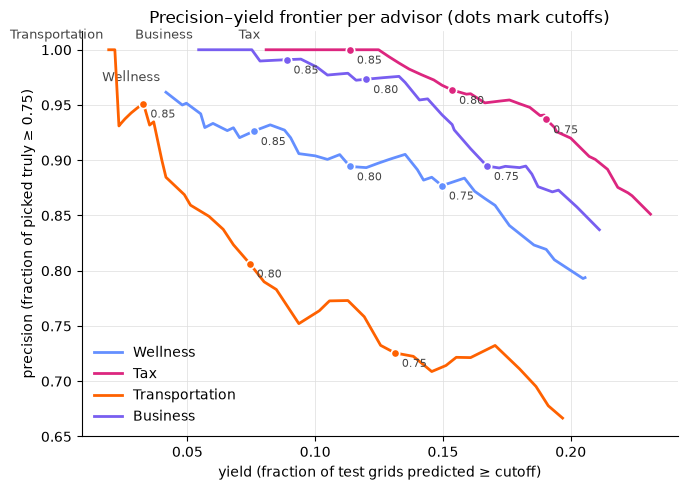

In [51]:
def plot_precision_vs_yield(feature_fn, model_fn, cutoffs=np.arange(0.70, 0.901, 0.005),
                            annotate_cutoffs=(0.75, 0.80, 0.85)):
    """One curve per advisor: precision (y) against yield (x), cutoff implicit along the curve."""
    ADVISOR_COLORS = {"Wellness": "#648FFF", "Tax": "#DC267F",
                      "Transportation": "#FE6100", "Business": "#785EF0"}
    C_INK, C_GRID = "#444444", "#DDDDDD"
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.grid(color=C_GRID, linewidth=0.5, zorder=0)

    for advisor, name in enumerate(ADVISOR_NAMES):
        grids_subset, ratings_subset = select_rated_subset(grids, ratings[:, advisor])
        X = feature_fn(grids_subset)
        X_train, X_test, y_train, y_test = train_test_split(X, ratings_subset, random_state=0)
        model = model_fn()
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

        precision, yield_frac = [], []
        for c in cutoffs:
            picked = preds >= c
            if picked.any():
                yield_frac.append(picked.mean())
                precision.append((y_test[picked] >= 0.75).mean())
        precision, yield_frac = np.array(precision), np.array(yield_frac)

        color = ADVISOR_COLORS[name]
        ax.plot(yield_frac, precision, color=color, linewidth=2, label=name, zorder=3)
        # direct label at the strict-cutoff (low-yield) end of the curve
        ax.annotate(name, (yield_frac[-1], precision[-1]), xytext=(-4, 8),
                    textcoords="offset points", ha="right", color=C_INK, fontsize=9)
        # pin a few cutoff values so curve points map back to thresholds
        for c in annotate_cutoffs:
            i = int(np.argmin(np.abs(cutoffs[:len(precision)] - c)))
            ax.plot(yield_frac[i], precision[i], "o", color=color, markersize=6,
                    markeredgecolor="white", markeredgewidth=1.2, zorder=4)
            ax.annotate(f"{c:.2f}", (yield_frac[i], precision[i]), xytext=(5, -10),
                        textcoords="offset points", color=C_INK, fontsize=8)

    ax.set_xlabel("yield (fraction of test grids predicted ≥ cutoff)")
    ax.set_ylabel("precision (fraction of picked truly ≥ 0.75)")
    ax.set_title("Precision–yield frontier per advisor (dots mark cutoffs)")
    ax.spines[["right", "top"]].set_visible(False)
    ax.legend(loc="lower left", frameon=False)
    plt.tight_layout()
    plt.show()


plot_precision_vs_yield(onehot_plus_adjacency,
                        lambda: HistGradientBoostingRegressor(random_state=0))

## Does diversity selection hunt the model's mistakes? (winner's curse check)

The calibration numbers above are measured on *typical* test grids. But the diversity stage will
deliberately pick grids at the **periphery** of the certified pool — the unusual ones, far from
everything else in Hamming space. Those are exactly the grids with the fewest similar training
examples (larger model errors), and a grid can even land in the pool *because* of an upward error,
making it look both valid and attractively "different." If so, the realized validity of a
diversity-selected subset will be **lower** than the pool's measured precision.

The experiment, per advisor, entirely on held-out test grids:
1. Certify test grids at a cutoff (prediction ≥ `cutoff`) → the pool, with known true precision.
2. From the pool, greedily pick `k` grids maximizing spread (max–min Hamming distance — a stand-in
   for the later diversity optimizer).
3. Control: random subsets of the same size `k` (their precision ≈ pool precision by construction).
4. Compare true validity rates: **diverse-picked vs. random-picked**.

Read the `curse` column (diverse − random precision): ≈ 0 means calibration transfers to diverse
picks and the pool precision can be trusted as-is; clearly negative means diverse picks need extra
safety margin (or per-grid uncertainty) beyond what the calibration table suggests. (`k` defaults to
50 so the pick is a strict subset of every advisor's pool at the default cutoff; with only ~40–200
pool grids per advisor, treat single runs as indicative, not exact.)

In [52]:
def hamming_matrix(grid_arr):
    """Pairwise normalized Hamming distance between grids: fraction of the 49 cells that differ."""
    flat = grid_arr.reshape(len(grid_arr), -1)
    return (flat[:, None, :] != flat[None, :, :]).mean(axis=2)


def greedy_diverse_indices(dist, k, start):
    """Max-min greedy pick: repeatedly add the grid farthest from everything picked so far."""
    selected = [start]
    min_dist = dist[start].copy()
    for _ in range(k - 1):
        min_dist[selected] = -1.0  # never re-pick
        nxt = int(np.argmax(min_dist))
        selected.append(nxt)
        min_dist = np.minimum(min_dist, dist[nxt])
    return np.array(selected)


def winners_curse_check(feature_fn, model_fn, cutoff=0.78, k=50, n_random=500, seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for advisor in range(4):
        grids_subset, ratings_subset = select_rated_subset(grids, ratings[:, advisor])
        X = feature_fn(grids_subset)
        idx = np.arange(len(grids_subset))
        X_tr, X_te, y_tr, y_te, _, idx_te = train_test_split(X, ratings_subset, idx, random_state=0)
        model = model_fn()
        model.fit(X_tr, y_tr)
        preds = model.predict(X_te)

        certified = preds >= cutoff
        pool_grids = grids_subset[idx_te[certified]]
        pool_valid = y_te[certified] >= VALID_THRESHOLD
        m = len(pool_grids)
        kk = min(k, m)

        # diverse pick, anchored at the model's most confident pool grid
        dist = hamming_matrix(pool_grids)
        picked = greedy_diverse_indices(dist, kk, start=int(np.argmax(preds[certified])))
        diverse_prec = pool_valid[picked].mean()

        # random-pick control (same size, from the same pool)
        random_prec = np.mean([pool_valid[rng.choice(m, kk, replace=False)].mean()
                               for _ in range(n_random)])

        rows.append({"advisor": ADVISOR_NAMES[advisor], "pool_size": m, "picked": kk,
                     "pool_precision": pool_valid.mean(),
                     "random_pick_precision": random_prec,
                     "diverse_pick_precision": diverse_prec,
                     "curse": diverse_prec - random_prec})
    return pd.DataFrame(rows).set_index("advisor").round(3)


winners_curse_check(onehot_plus_adjacency, lambda: HistGradientBoostingRegressor(random_state=0))

,pool_size,picked,pool_precision,random_pick_precision,diverse_pick_precision,curse
advisor,,,,,,
Wellness,161,50,0.901,0.901,0.92,0.019
Tax,215,50,0.953,0.955,0.98,0.025
Transportation,127,50,0.764,0.764,0.76,-0.004
Business,176,50,0.955,0.954,0.92,-0.034


## Scratch space

Ideas to try next (keep `run_experiment` as the common yardstick):
- More spatial features: distance-to-nearest-park per residential cell, row/column counts, cluster sizes
- Per-advisor feature sets (each advisor likely keys on different structure)
- Hyperparameter tuning / XGBoost / LightGBM
- A small CNN on the one-hot 7×7×5 tensor (the grid is an image; convolutions see adjacency natively)
- Uncertainty estimates (ensemble spread, quantile regression) to set per-grid safety margins instead of one global cutoff